# 决策树课堂笔记：从基尼不纯度到树的分裂

本 Notebook 按 2026-11 版《机器学习课堂笔记》第 5 章整理，覆盖：

- 决策树的基本概念：根节点、内部节点、分支、叶子节点
- 基尼不纯度及其公式
- 加权基尼与基尼增益
- 第二层分裂：跳过无区分能力的特征
- 决策树的停止条件
- 数值特征与阈值：候选分割点、最优阈值
- sklearn 决策树的训练、节点读取和可视化

依赖：

```bash
pip install numpy pandas scikit-learn matplotlib
```

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
np.set_printoptions(precision=4, suppress=True)

## 5.1 决策树的概念

决策树就是一套分层判断的“问答流程图”：

- **根节点**：最开头第一个判断问题；
- **内部节点**：中间的每一个提问、判断条件；
- **分支**：每个问题的不同答案；
- **叶子节点**：最后的结论，不再继续分叉。

决策树的目标：用尽量少的问题，把数据尽量分开，让同一个叶子里的类别尽量一致、纯净。

哪个特征放在前面，不是随便排的，而是算法根据“区分能力”算出来的：优先把最能区分数据的特征放在上层。

## 5.2 基尼不纯度

基尼不纯度衡量一堆样本有多“混杂”：

- 基尼值越大，数据越杂；
- 基尼值越小，数据越纯。

直观理解：闭上眼睛，有放回地连续抽两张卡片，**抽到不同类别的概率**就是基尼不纯度。

设正类占比为 $p$，负类占比为 $1-p$：

$$
\text{Gini}
=1-p^2-(1-p)^2
=2p(1-p)
$$

多分类时：

$$
\text{Gini}=1-\sum_{k=1}^{K}p_k^2
$$

其中 $p_k$ 是第 $k$ 类样本在集合中的占比。

基尼只是衡量混乱程度，和预测准不准不是一回事。决策树分裂时追求的是：**分裂后基尼下降**。

In [2]:
def gini(y):
    """二分类基尼不纯度：Gini = 1 - p^2 - (1-p)^2。"""
    y = np.array(y)
    if len(y) == 0:
        return 0.0
    p = y.mean()
    return 1 - p**2 - (1 - p)**2


for name, labels in [
    ("全部违约", [1, 1, 1, 1]),
    ("全部正常", [0, 0, 0, 0]),
    ("一半一半", [1, 1, 0, 0]),
    ("1 个违约 3 个正常", [1, 0, 0, 0]),
]:
    print(f"{name} 基尼={gini(labels):.3f}")

全部违约 基尼=0.000
全部正常 基尼=0.000
一半一半 基尼=0.500
1 个违约 3 个正常 基尼=0.375


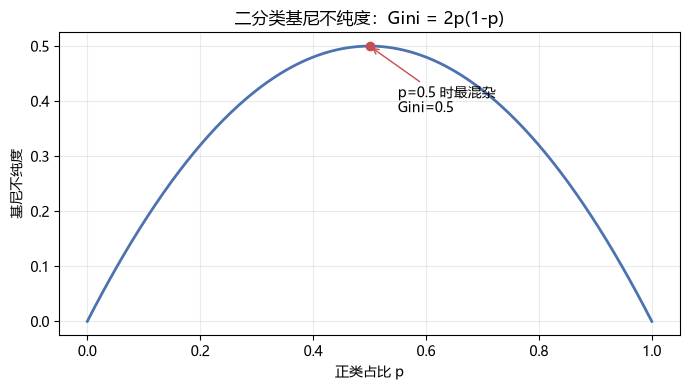

In [3]:
p_grid = np.linspace(0, 1, 300)
gini_grid = 2 * p_grid * (1 - p_grid)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(p_grid, gini_grid, color="#4C72B0", linewidth=2)
ax.scatter([0.5], [0.5], color="#C44E52", zorder=3)
ax.annotate("p=0.5 时最混杂\nGini=0.5", xy=(0.5, 0.5), xytext=(0.55, 0.38),
            arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.set_xlabel("正类占比 p")
ax.set_ylabel("基尼不纯度")
ax.set_title("二分类基尼不纯度：Gini = 2p(1-p)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("images/notes13_fig_gini.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.3 加权基尼

决策树一次分裂会把节点切成左右两组。两组的样本数一般不同，不能直接对两个基尼求简单平均，而要按人数加权：

$$
\text{Gini}_{\text{split}}
=\frac{n_L}{n}\text{Gini}_L
+\frac{n_R}{n}\text{Gini}_R
$$

其中：

- $n$：分裂前节点样本数；
- $n_L,n_R$：左右子节点样本数；
- $\text{Gini}_L,\text{Gini}_R$：左右子节点自己的基尼。

基尼增益：

$$
\Delta\text{Gini}
=\text{Gini}_{\text{parent}}
-\text{Gini}_{\text{split}}
$$

**加权基尼越小，这次分裂越好。** 决策树会在所有候选分裂中，选择加权基尼最小的那个。

例子：左边 7 人、基尼 0.4；右边 3 人、基尼 0.1：

$$
\text{Gini}_{\text{split}}
=0.4\times\frac{7}{10}+0.1\times\frac{3}{10}
=0.31
$$

In [4]:
case1 = pd.DataFrame({
    "有房产":   ["无", "有", "无", "无", "无", "无", "无", "有", "无", "有"],
    "工作稳定": ["稳定", "稳定", "稳定", "稳定", "不稳定", "不稳定", "不稳定", "不稳定", "稳定", "稳定"],
    "信用记录": ["较差", "较差", "良好", "较差", "较差", "良好", "较差", "良好", "良好", "良好"],
    "是否违约": [1, 0, 0, 1, 1, 0, 1, 0, 0, 0],
}, index=range(1, 11))

X1 = pd.DataFrame({
    "有房产": (case1["有房产"] == "有").astype(int),
    "工作稳定": (case1["工作稳定"] == "稳定").astype(int),
    "信用良好": (case1["信用记录"] == "良好").astype(int),
})
y1 = case1["是否违约"].to_numpy()

display(case1)
display(X1)

,有房产,工作稳定,信用记录,是否违约
1,无,稳定,较差,1
2,有,稳定,较差,0
3,无,稳定,良好,0
4,无,稳定,较差,1
5,无,不稳定,较差,1
6,无,不稳定,良好,0
7,无,不稳定,较差,1
8,有,不稳定,良好,0
9,无,稳定,良好,0
10,有,稳定,良好,0


,有房产,工作稳定,信用良好
1,0,1,0
2,1,1,0
3,0,1,1
4,0,1,0
5,0,0,0
6,0,0,1
7,0,0,0
8,1,0,1
9,0,1,1
10,1,1,1


In [5]:
def weighted_gini(y, mask):
    """mask=True 去右边，False 去左边；返回左右基尼和加权基尼。"""
    left, right = y[~mask], y[mask]
    gl, gr = gini(left), gini(right)
    wg = (len(left) * gl + len(right) * gr) / len(y)
    return gl, gr, wg


for col in X1.columns:
    mask = X1[col].to_numpy() == 1
    gl, gr, wg = weighted_gini(y1, mask)
    print(
        f"{col:<5} 左 {(~mask).sum()} 人（违约 {y1[~mask].sum()}）基尼 {gl:.4f}  "
        f"右 {mask.sum()} 人（违约 {y1[mask].sum()}）基尼 {gr:.4f}  "
        f"加权基尼 {wg:.4f}"
    )

有房产   左 7 人（违约 4）基尼 0.4898  右 3 人（违约 0）基尼 0.0000  加权基尼 0.3429
工作稳定  左 4 人（违约 2）基尼 0.5000  右 6 人（违约 2）基尼 0.4444  加权基尼 0.4667
信用良好  左 5 人（违约 4）基尼 0.3200  右 5 人（违约 0）基尼 0.0000  加权基尼 0.1600


以“信用记录”为例：

- 信用较差 5 人，其中 4 人违约，$p=4/5=0.8$，基尼 $=1-0.8^2-0.2^2=0.32$；
- 信用良好 5 人全部正常，基尼 $=0$；
- 加权基尼 $=0.32\times\frac{5}{10}+0\times\frac{5}{10}=0.16$。

三个特征的加权基尼分别是：

- 有房产：0.3429
- 工作稳定：0.4667
- 信用良好：0.1600

信用记录最小，所以根节点先问“信用良好吗？”。

## 5.4 第二层：跳过无区分能力的特征

根节点按“信用良好”切开后：

- 信用良好的一组基尼为 0，已经纯净，直接成为叶子节点；
- 信用较差的一组还有 4 个违约、1 个正常，基尼 0.32，需要继续分裂。

在信用较差的 5 个人里，“信用良好”全部等于 0，所有人取值相同，这个特征无法再区分他们，必须跳过。

如果某个特征在当前节点所有样本上取值都相同，它没有区分能力，不参与加权基尼计算。

In [6]:
sub = X1["信用良好"].to_numpy() == 0
Xs, ys = X1[sub], y1[sub]

print("当前节点：", len(ys), "人，违约", ys.sum(), "人，基尼", round(gini(ys), 4))

for col in X1.columns:
    vals = Xs[col].to_numpy()
    if len(set(vals)) == 1:
        print(f"{col:<5} 所有人都一样，跳过")
        continue
    gl, gr, wg = weighted_gini(ys, vals == 1)
    print(f"{col:<5} 加权基尼 {wg:.4f}")

当前节点： 5 人，违约 4 人，基尼 0.32
有房产   加权基尼 0.0000
工作稳定  加权基尼 0.2667
信用良好  所有人都一样，跳过


第二层结果：

- 有房产：加权基尼 0，切完两组都纯净，选它；
- 工作稳定：加权基尼 0.2667，也能分，但不如有房产；
- 信用良好：所有人取值相同，跳过。

分裂后继续对新子集重复：基尼为 0 就停止；还混杂就继续找最小加权基尼的特征。

## 5.5 决策树什么时候停止分裂

两个最基础的停止条件：

1. **节点已经纯净**：基尼 = 0，节点里所有标签相同；
2. **没有特征可以继续拆分**：剩下的特征在当前节点无法把样本分开。

sklearn 默认会一直分裂，直到所有叶子节点都纯净。这样长满的树很容易过拟合，后续需要用 `max_depth`、`min_samples_leaf` 等参数剪枝。

In [7]:
tree1 = DecisionTreeClassifier(random_state=0).fit(X1, y1)
t = tree1.tree_

for k in range(t.node_count):
    if t.children_left[k] == -1:
        kind = "叶子"
    else:
        kind = f"按 {X1.columns[t.feature[k]]} <= {t.threshold[k]:.3f} 划分"
    print(f"节点{k}: {t.n_node_samples[k]} 人，基尼 {t.impurity[k]:.4f}，{kind}")

节点0: 10 人，基尼 0.4800，按 信用良好 <= 0.500 划分
节点1: 5 人，基尼 0.3200，按 有房产 <= 0.500 划分
节点2: 4 人，基尼 0.0000，叶子
节点3: 1 人，基尼 0.0000，叶子
节点4: 5 人，基尼 0.0000，叶子


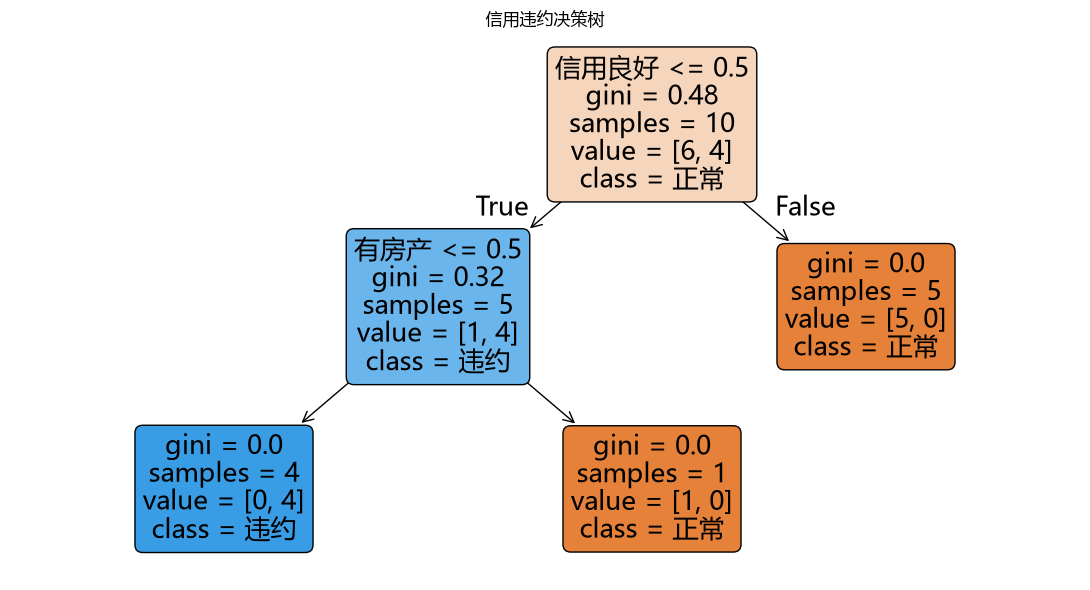

In [8]:
fig, ax = plt.subplots(figsize=(11, 6))
plot_tree(
    tree1,
    feature_names=list(X1.columns),
    class_names=["正常", "违约"],
    filled=True,
    rounded=True,
    ax=ax,
)
ax.set_title("信用违约决策树")
fig.tight_layout()
fig.savefig("images/notes13_fig_tree_case.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.6 数值特征与阈值

前面的特征是 0/1 类别，问题很好提。月收入这种连续数值特征不能问“收入等于 3 吗”，因为取值太碎、泛化差。

决策树对数值特征统一问：

$$
x \le t \;?
$$

其中 $t$ 是分割阈值。回答只有“是/否”，刚好把节点切成左右两支。

### 5.6.1 怎么找阈值

1. 把该特征的取值从小到大排序；
2. 在相邻两个不同取值的中间生成候选阈值：

$$
t_i=\frac{x_i+x_{i+1}}{2}
$$

3. 对每个候选阈值计算分裂后的加权基尼；
4. 选择加权基尼最小（基尼增益最大）的阈值。

In [9]:
income = np.array([3, 5, 6, 8, 9, 11, 13, 14, 16, 19])
y2 = np.array([1, 1, 1, 0, 1, 0, 0, 0, 0, 0])

display(pd.DataFrame({"月收入": income, "是否违约": y2}, index=range(1, 11)).T)

xs = np.unique(income)
mids = (xs[:-1] + xs[1:]) / 2

for t_ in mids:
    gl, gr, wg = weighted_gini(y2, income > t_)
    print(f"月收入 <= {t_:>4}: 左基尼 {gl:.4f}  右基尼 {gr:.4f}  加权基尼 {wg:.4f}")

best = mids[np.argmin([weighted_gini(y2, income > t_)[2] for t_ in mids])]
print("最好的阈值:", best)

,1,2,3,4,5,6,7,8,9,10
月收入,3,5,6,8,9,11,13,14,16,19
是否违约,1,1,1,0,1,0,0,0,0,0


月收入 <=  4.0: 左基尼 0.0000  右基尼 0.4444  加权基尼 0.4000
月收入 <=  5.5: 左基尼 0.0000  右基尼 0.3750  加权基尼 0.3000
月收入 <=  7.0: 左基尼 0.0000  右基尼 0.2449  加权基尼 0.1714
月收入 <=  8.5: 左基尼 0.3750  右基尼 0.2778  加权基尼 0.3167
月收入 <= 10.0: 左基尼 0.3200  右基尼 0.0000  加权基尼 0.1600
月收入 <= 12.0: 左基尼 0.4444  右基尼 0.0000  加权基尼 0.2667
月收入 <= 13.5: 左基尼 0.4898  右基尼 0.0000  加权基尼 0.3429
月收入 <= 15.0: 左基尼 0.5000  右基尼 0.0000  加权基尼 0.4000
月收入 <= 17.5: 左基尼 0.4938  右基尼 0.0000  加权基尼 0.4444
最好的阈值: 10.0


在收入例子中，最优阈值是 **10.0**：

- 月收入 ≤ 10 的一侧：基尼约 0.32；
- 月收入 > 10 的一侧：基尼 0；
- 加权基尼约 0.16，是所有候选阈值中最小的。

In [10]:
X_income = income.reshape(-1, 1)
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=1,
    random_state=42,
).fit(X_income, y2)

tree = dt.tree_
best_th_sk = tree.threshold[0]
left_idx = tree.children_left[0]
right_idx = tree.children_right[0]
gl_sk = tree.impurity[left_idx]
gr_sk = tree.impurity[right_idx]
n_left = tree.n_node_samples[left_idx]
n_right = tree.n_node_samples[right_idx]
wg_sk = (n_left * gl_sk + n_right * gr_sk) / (n_left + n_right)

print(f"模型找到的最优分割阈值: {best_th_sk}")
print(f"左分支基尼 gl={gl_sk:.4f}，样本数={n_left}")
print(f"右分支基尼 gr={gr_sk:.4f}，样本数={n_right}")
print(f"对应加权基尼 wg={wg_sk:.4f}")
print("\n树规则文本：")
print(export_text(dt, feature_names=["月收入"]))

模型找到的最优分割阈值: 10.0
左分支基尼 gl=0.3200，样本数=5
右分支基尼 gr=0.0000，样本数=5
对应加权基尼 wg=0.1600

树规则文本：
|--- 月收入 <= 10.00
|   |--- class: 1
|--- 月收入 >  10.00
|   |--- class: 0



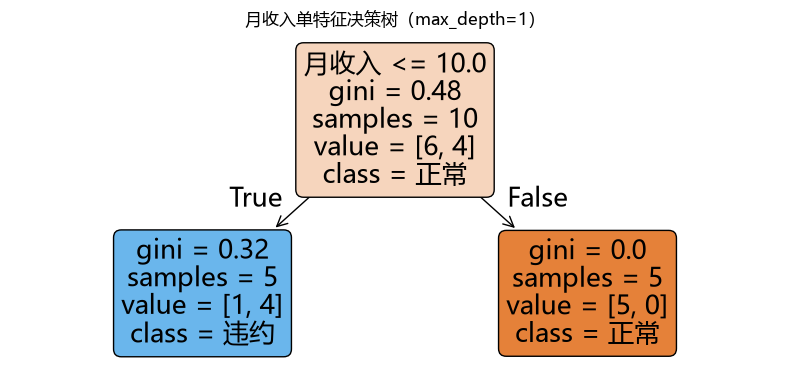

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_tree(
    dt,
    feature_names=["月收入"],
    class_names=["正常", "违约"],
    filled=True,
    rounded=True,
    ax=ax,
)
ax.set_title("月收入单特征决策树（max_depth=1）")
fig.tight_layout()
fig.savefig("images/notes13_fig_tree_income.png", dpi=150, bbox_inches="tight")
plt.show()

## 5.7 小结

- 基尼不纯度衡量节点混杂程度：$Gini=1-\sum p_k^2$，二分类为 $2p(1-p)$；
- 一次分裂用加权基尼评分：$Gini_{split}=\frac{n_L}{n}Gini_L+\frac{n_R}{n}Gini_R$；
- 加权基尼越小，分裂越好；基尼增益 = 父节点基尼 − 分裂后加权基尼；
- 当前节点特征取值全相同，则跳过该特征；
- 停止条件：节点纯净，或没有特征可继续分裂；
- 数值特征在相邻取值的中点生成候选阈值，选择加权基尼最小的阈值；
- sklearn 默认长到纯净，容易过拟合，需要 `max_depth`、`min_samples_leaf` 等参数控制。